In [35]:
import numpy as np  
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
df=pd.read_csv('smart_city_traffic_mobility.csv')
df.head()

,record_id,city_zone,road_id,intersection_id,latitude,longitude,road_type,lanes,speed_limit,vehicle_count,...,traffic_camera_count,iot_sensor_health,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,congestion_score,emission_estimate,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,16.8,39.14,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,150,...,1,Optimal,60,18,0,150.0,18.4,36.09,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,186,...,1,Optimal,60,18,0,186.0,20.7,44.01,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,17.8,38.47,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,168,...,1,Optimal,60,18,0,168.0,17.3,40.28,8.71,Low


In [37]:
selected_columns = [
    "city_zone",
    "road_type",
    "lanes",
    "speed_limit",
    "vehicle_count",
    "average_speed",
    "traffic_density",
    "queue_length",
    "hour",
    "is_weekend",
    "weather_condition",
    "congestion_level"
]

In [38]:
df_cleaned=df[selected_columns]
df_cleaned.head()

,city_zone,road_type,lanes,speed_limit,vehicle_count,average_speed,traffic_density,queue_length,hour,is_weekend,weather_condition,congestion_level
0,Financial District,Local Street,2,40,162,40.0,27.0,14.3,0,0,Clear,Low
1,Financial District,Local Street,2,40,150,37.7,25.0,12.0,1,0,Clear,Low
2,Financial District,Local Street,2,40,186,38.4,31.0,2.5,2,0,Clear,Low
3,Financial District,Local Street,2,40,162,38.9,27.0,6.0,3,0,Clear,Low
4,Financial District,Local Street,2,40,168,40.0,28.0,13.4,4,0,Clear,Low


In [39]:
df_cleaned.isnull().sum()

city_zone            0
road_type            0
lanes                0
speed_limit          0
vehicle_count        0
average_speed        0
traffic_density      0
queue_length         0
hour                 0
is_weekend           0
weather_condition    0
congestion_level     0
dtype: int64

In [40]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 204000 entries, 0 to 203999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   city_zone          204000 non-null  str    
 1   road_type          204000 non-null  str    
 2   lanes              204000 non-null  int64  
 3   speed_limit        204000 non-null  int64  
 4   vehicle_count      204000 non-null  int64  
 5   average_speed      204000 non-null  float64
 6   traffic_density    204000 non-null  float64
 7   queue_length       204000 non-null  float64
 8   hour               204000 non-null  int64  
 9   is_weekend         204000 non-null  int64  
 10  weather_condition  204000 non-null  str    
 11  congestion_level   204000 non-null  str    
dtypes: float64(3), int64(5), str(4)
memory usage: 25.0 MB


In [41]:
df_cleaned['speed_limit'].unique()

array([40, 60, 90])

In [42]:
df_cleaned['lanes'].unique()

array([2, 3, 4])

In [43]:
df_cleaned['congestion_level'].unique()

<ArrowStringArray>
['Low', 'High', 'Severe', 'Moderate']
Length: 4, dtype: str

In [44]:
numerical_col=df_cleaned.select_dtypes(include='number')

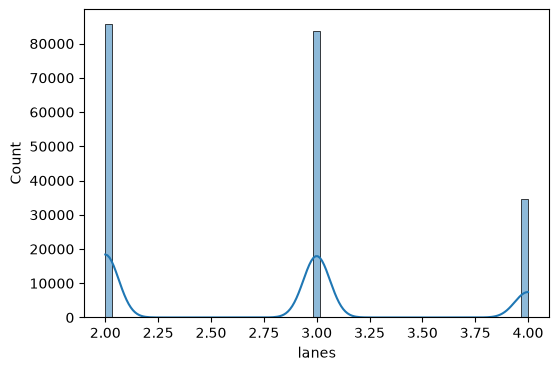

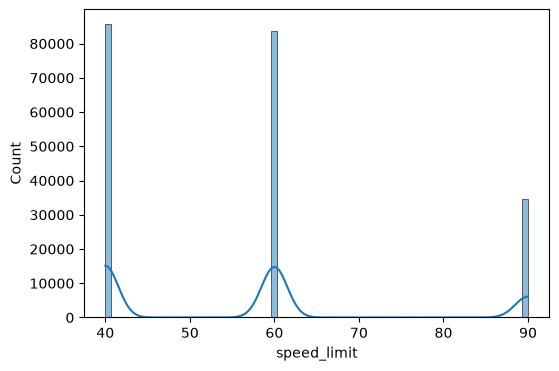

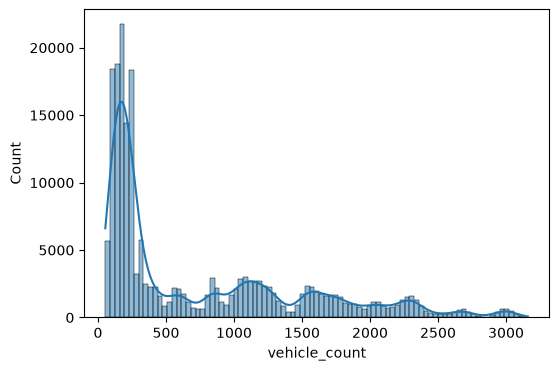

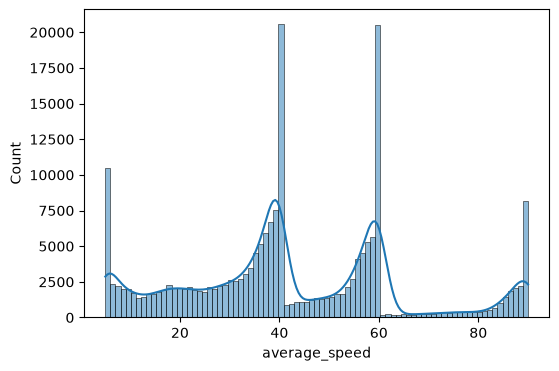

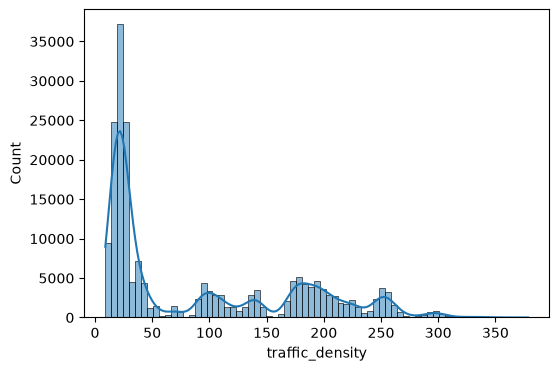

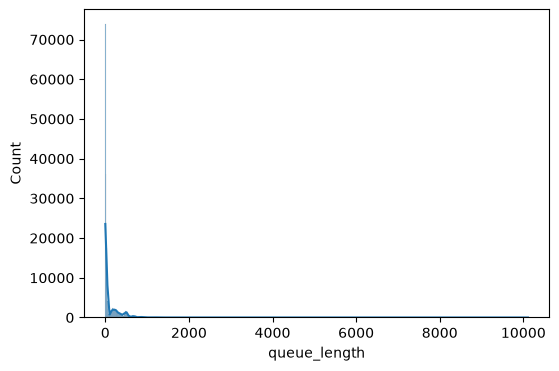

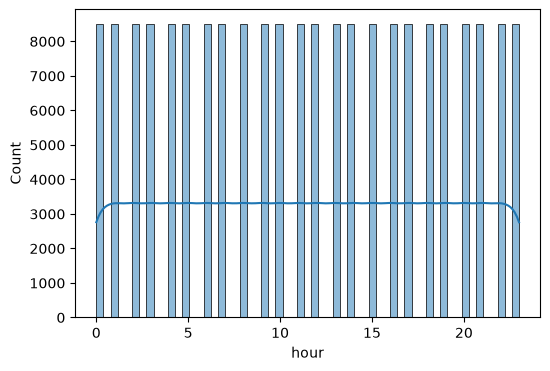

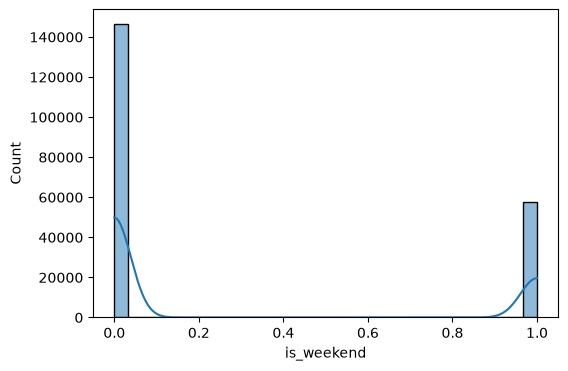

In [45]:
for col in numerical_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.histplot(df_cleaned[col],kde=True)

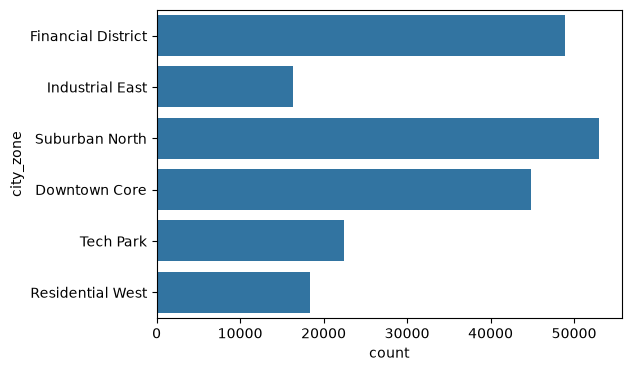

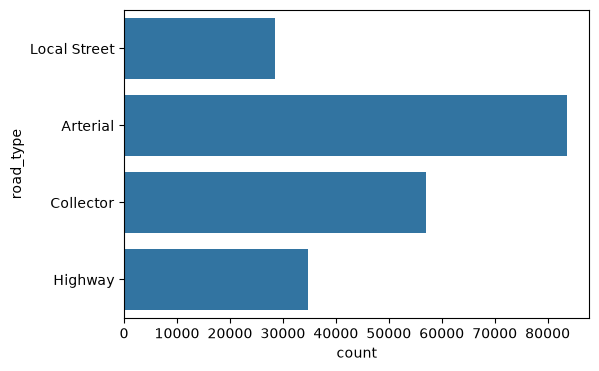

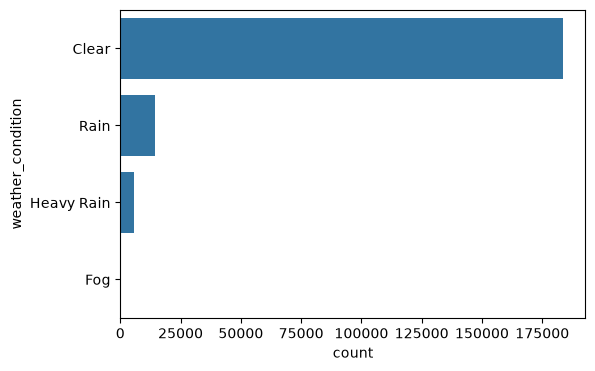

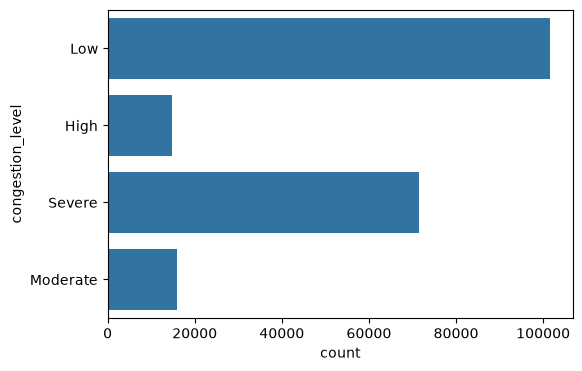

In [46]:
cat_col=df_cleaned.select_dtypes(exclude='number')
for col in cat_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.countplot(df_cleaned[col])

In [47]:
df_cleaned.head()

,city_zone,road_type,lanes,speed_limit,vehicle_count,average_speed,traffic_density,queue_length,hour,is_weekend,weather_condition,congestion_level
0,Financial District,Local Street,2,40,162,40.0,27.0,14.3,0,0,Clear,Low
1,Financial District,Local Street,2,40,150,37.7,25.0,12.0,1,0,Clear,Low
2,Financial District,Local Street,2,40,186,38.4,31.0,2.5,2,0,Clear,Low
3,Financial District,Local Street,2,40,162,38.9,27.0,6.0,3,0,Clear,Low
4,Financial District,Local Street,2,40,168,40.0,28.0,13.4,4,0,Clear,Low


In [48]:
df_cleaned.columns

Index(['city_zone', 'road_type', 'lanes', 'speed_limit', 'vehicle_count',
       'average_speed', 'traffic_density', 'queue_length', 'hour',
       'is_weekend', 'weather_condition', 'congestion_level'],
      dtype='str')

In [49]:
df_cleaned['is_weekend'].value_counts()

is_weekend
0    146400
1     57600
Name: count, dtype: int64

In [50]:
df_cleaned.shape

(204000, 12)

In [51]:
all_cat_col=['city_zone', 'road_type','weather_condition']
numerical_col=['lanes', 'speed_limit', 'vehicle_count',
       'average_speed', 'traffic_density', 'queue_length', 'hour']
boolean_col=['is_weekend']
target_col=['congestion_level']

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
from sklearn.preprocessing import OneHotEncoder

In [55]:
normal_pipeline=Pipeline(steps=[
    ('scaling',StandardScaler())
])
cat_pipeline=Pipeline(steps=[
    ('one_hot',OneHotEncoder(handle_unknown='ignore'))
])

In [56]:
X=df_cleaned[all_cat_col+numerical_col+boolean_col]
y=df_cleaned[target_col]

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train,X_test,y_train,y_test=train_test_split(X,y,stratify=y,test_size=0.20)

In [59]:
from sklearn.preprocessing import LabelEncoder

In [60]:
le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

c:\Users\BikramBidisha\venvs\ml312\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\BikramBidisha\venvs\ml312\Lib\site-packages\sklearn\preprocessing\_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


In [61]:
y_train

array([3, 1, 3, ..., 1, 1, 3], shape=(163200,))

In [62]:
preprocessor=ColumnTransformer(transformers=[
    ('numerical',normal_pipeline,numerical_col),
    ('categorical',cat_pipeline,cat_col)
])

In [63]:
from sklearn.linear_model import LinearRegression

In [64]:
linear_pipeline=Pipeline(steps=[
    ('preprocessing',preprocessor),
    ('linear_model',LinearRegression())
]
)

In [65]:
linear_pipeline.fit(X_train,y_train)

ValueError: No valid specification of the columns. Only a scalar, list or slice of all integers or all strings, or boolean mask is allowed